<a href="https://colab.research.google.com/github/sandyy221/244107020029-mobile-course/blob/main/Jobsheet_13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Praktikum 1

## Langkah 1 - Buat Dataset Sederhana (XOR)
Dataset XOR dipakai karena tidak dapat dipisahkan oleh satu garis lurus (*non-linearly separable*), sehingga membutuhkan minimal satu hidden layer.

In [ ]:
import numpy as np

# Dataset XOR
X = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([[0],[1],[1],[0]])

## Langkah 2 - Inisialisasi Bobot dan Bias
Menentukan ukuran jaringan (2 input, 2 neuron hidden, 1 output), *learning rate*, bobot awal acak, bias awal nol, serta fungsi aktivasi sigmoid beserta turunannya.

In [ ]:
# Parameter
input_size = 2
hidden_size = 2
output_size = 1
lr = 0.1

# Inisialisasi bobot
W1 = np.random.randn(input_size, hidden_size)
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size)
b2 = np.zeros((1, output_size))

# Fungsi aktivasi
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

## Langkah 3 sampai 5 - Forward Pass, Hitung Error, Backpropagation, dan Update Bobot
Pada setiap epoch dilakukan: forward pass, hitung error, backpropagation, lalu update bobot dengan gradient descent.
Loss (MSE) dicetak setiap 1000 epoch.

> Bobot awal acak dan tidak memakai `seed`, sehingga angka loss dan prediksi dapat sedikit berbeda setiap kali sel dijalankan.

In [ ]:
# Training
for epoch in range(10000):
    # Forward pass
    z1 = np.dot(X, W1) + b1
    a1 = sigmoid(z1)
    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)

    # Hitung error
    error = y - a2

    # Backpropagation
    d_a2 = error * sigmoid_derivative(a2)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2.T) * sigmoid_derivative(a1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    # Update bobot
    W1 += lr * d_W1
    b1 += lr * d_b1
    W2 += lr * d_W2
    b2 += lr * d_b2

    if epoch % 1000 == 0:
        loss = np.mean(np.square(error))
        print(f"Epoch {epoch}, Loss: {loss}")

# Output akhir
print("Prediksi:")
print(a2)

Epoch 0, Loss: 0.24969879470585418
Epoch 1000, Loss: 0.2168030352163814
Epoch 2000, Loss: 0.17823322967822305
Epoch 3000, Loss: 0.10874258648375523
Epoch 4000, Loss: 0.02803175551414718
Epoch 5000, Loss: 0.012048416462750944
Epoch 6000, Loss: 0.007201756981914712
Epoch 7000, Loss: 0.005019951004344192
Epoch 8000, Loss: 0.0038107101270161534
Epoch 9000, Loss: 0.0030519478537995993
Prediksi:
[[0.04369616]
 [0.94759128]
 [0.94759122]
 [0.05234587]]


## Tugas 1
- Ubah jumlah neuron hidden layer menjadi 3.
- Bandingkan hasil loss dengan konfigurasi awal.
- Tambahkan fungsi aktivasi ReLU dan bandingkan hasil.


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

def relu(x):
    return np.maximum(0, x)

def relu_derivative(a):
    # turunan ReLU: 1 jika aktivasi > 0, selain itu 0
    return (a > 0).astype(float)

def train_xor(hidden_size=2, hidden_act='sigmoid', epochs=10000, lr=0.1, seed=42):
    rng = np.random.RandomState(seed)
    W1 = rng.randn(2, hidden_size)
    b1 = np.zeros((1, hidden_size))
    W2 = rng.randn(hidden_size, 1)
    b2 = np.zeros((1, 1))

    act = sigmoid if hidden_act == 'sigmoid' else relu
    act_d = sigmoid_derivative if hidden_act == 'sigmoid' else relu_derivative

    losses = []
    for epoch in range(epochs):
        # Forward pass
        a1 = act(np.dot(X, W1) + b1)
        a2 = sigmoid(np.dot(a1, W2) + b2)

        # Hitung error
        error = y - a2
        losses.append(np.mean(np.square(error)))

        # Backpropagation
        d_a2 = error * sigmoid_derivative(a2)
        d_a1 = np.dot(d_a2, W2.T) * act_d(a1)

        # Update bobot
        W2 += lr * np.dot(a1.T, d_a2)
        b2 += lr * np.sum(d_a2, axis=0, keepdims=True)
        W1 += lr * np.dot(X.T, d_a1)
        b1 += lr * np.sum(d_a1, axis=0, keepdims=True)

    return losses, a2

konfigurasi = {
    'Hidden 2 - Sigmoid (awal)': (2, 'sigmoid'),
    'Hidden 3 - Sigmoid':        (3, 'sigmoid'),
    'Hidden 2 - ReLU':           (2, 'relu'),
    'Hidden 3 - ReLU':           (3, 'relu'),
}

# Perbandingan dengan seed yang sama (seed=42)
hasil_xor = {}
for nama, (h, act_name) in konfigurasi.items():
    hasil_xor[nama] = train_xor(hidden_size=h, hidden_act=act_name, seed=42)

tabel = pd.DataFrame({
    nama: {f'Loss epoch {e}': hasil_xor[nama][0][e] for e in [0, 1000, 5000, 9999]}
    for nama in konfigurasi
}).T
print("Loss pada seed=42:")
display(tabel)

print("\nPrediksi akhir (dibulatkan 3 desimal):")
for nama in konfigurasi:
    print(f"{nama:28s}", np.round(hasil_xor[nama][1].ravel(), 3))

Loss pada seed=42:


,Loss epoch 0,Loss epoch 1000,Loss epoch 5000,Loss epoch 9999
Hidden 2 - Sigmoid (awal),0.255830,0.249406,0.138691,0.128227
Hidden 3 - Sigmoid,0.318245,0.205697,0.009992,0.002297
Hidden 2 - ReLU,0.261648,0.126387,0.125116,0.125047
Hidden 3 - ReLU,0.327478,0.012797,0.000846,0.000352



Prediksi akhir (dibulatkan 3 desimal):
Hidden 2 - Sigmoid (awal)    [0.053 0.496 0.951 0.503]
Hidden 3 - Sigmoid           [0.025 0.953 0.951 0.063]
Hidden 2 - ReLU              [0.5   0.989 0.5   0.009]
Hidden 3 - ReLU              [0.03  0.986 0.986 0.012]


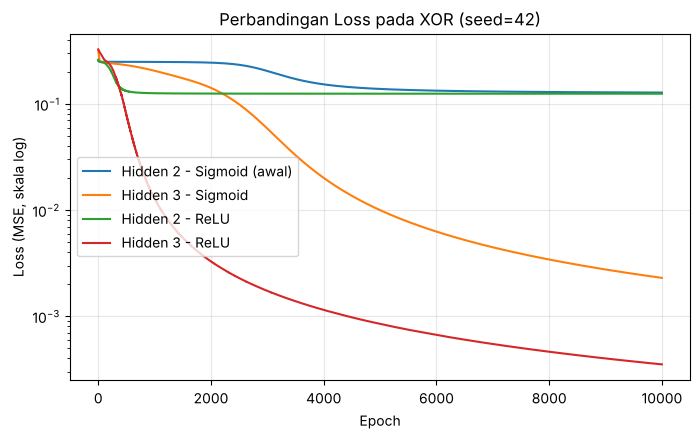

In [ ]:
# Kurva loss
plt.figure(figsize=(8, 4.5))
for nama in konfigurasi:
    plt.plot(hasil_xor[nama][0], label=nama)
plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE, skala log)')
plt.title('Perbandingan Loss pada XOR (seed=42)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Hasil dengan satu seed bisa kebetulan. Karena itu setiap konfigurasi diulang dengan 10 seed berbeda (bobot awal berbeda).
Sebuah percobaan dianggap **berhasil (konvergen)** bila loss akhir < 0,01.

In [ ]:
rekap = []
for nama, (h, act_name) in konfigurasi.items():
    finals = [train_xor(hidden_size=h, hidden_act=act_name, seed=s)[0][-1] for s in range(10)]
    rekap.append({
        'Konfigurasi': nama,
        'Rata-rata loss akhir': np.mean(finals),
        'Loss akhir terkecil': np.min(finals),
        'Loss akhir terbesar': np.max(finals),
        'Berhasil (dari 10 seed)': int(np.sum(np.array(finals) < 0.01)),
    })

pd.DataFrame(rekap)

,Konfigurasi,Rata-rata loss akhir,Loss akhir terkecil,Loss akhir terbesar,Berhasil (dari 10 seed)
0,Hidden 2 - Sigmoid (awal),0.040973,0.002433,0.127659,7
1,Hidden 3 - Sigmoid,0.002207,0.001713,0.002664,10
2,Hidden 2 - ReLU,0.187538,0.125051,0.250192,0
3,Hidden 3 - ReLU,0.104319,0.000213,0.250000,5


### Analisis Tugas 1

- **Hidden layer 3 neuron vs 2 neuron:** loss lebih kecil dan lebih konsisten. Pada seed=42, hidden 2 sigmoid macet di loss 0,128 (prediksi untuk input [0,1] dan [1,1] masih sekitar 0,5), sedangkan hidden 3 sigmoid mencapai loss 0,0023. Dengan 10 seed, hidden 3 sigmoid berhasil 10 dari 10, sedangkan hidden 2 sigmoid hanya 7 dari 10.
  Neuron yang lebih banyak memberi kapasitas lebih besar dan membuat jaringan lebih kecil kemungkinannya terjebak pada bobot awal yang buruk.
- **Menambah ReLU:** jika berhasil, ReLU jauh lebih cepat. Pada seed=42 hidden 3, loss ReLU di epoch 1000 sudah 0,0128 (sigmoid masih 0,2057) dan loss akhir 0,00035 (sigmoid 0,0023). Namun pada jaringan sekecil ini ReLU tidak stabil: hidden 2 ReLU tidak pernah berhasil (0 dari 10), hidden 3 ReLU berhasil 5 dari 10. Pada percobaan yang gagal, loss macet di sekitar 0,2 sampai 0,25, yaitu jaringan hanya mengeluarkan sekitar 0,5 untuk semua input.
  Penyebab yang paling mungkin adalah *dead ReLU*: neuron hidden yang keluarannya 0 untuk semua input tidak lagi menerima gradien sehingga bobotnya berhenti berubah.
- **Kesimpulan:** konfigurasi yang paling andal adalah hidden 3 neuron dengan sigmoid. Hidden 3 neuron dengan ReLU menghasilkan loss terkecil dan tercepat bila bobot awalnya cocok, tetapi hasilnya sangat bergantung pada inisialisasi.

---
# Praktikum 2
## JST dengan Keras: Klasifikasi Data Iris
Pada praktikum ini digunakan library **Keras**, yaitu API tingkat tinggi untuk membangun JST dengan mudah, sedangkan **TensorFlow** adalah framework yang mendukung Keras.

## Langkah 1 - Import Library

In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import tensorflow as tf

## Langkah 2 - Load Dataset
Memuat dataset Iris, mengubah label menjadi *one-hot encoding* (diperlukan karena loss `categorical_crossentropy` menuntut label berbentuk vektor), lalu membagi data 80% train dan 20% test.


In [ ]:
# Load dataset
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)

# One-hot encoding
encoder = OneHotEncoder(sparse_output=False)
y = encoder.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

## Langkah 3 - Bangun Model
Model `Sequential` dengan 2 hidden layer (10 dan 8 neuron, aktivasi ReLU) dan output layer 3 neuron (satu per kelas) dengan aktivasi softmax.

In [ ]:
# Bangun model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(4,)),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1794759585.381571    2459 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## Langkah 4 - Kompilasi dan Latih Model

In [ ]:
# Kompilasi
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Latih model
model.fit(X_train, y_train, epochs=50, batch_size=8)

Epoch 1/50


 1/15 ━━━━━━━━━━━━━━━━━━━━ 8s 590ms/step - accuracy: 0.5000 - loss: 1.3278

15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3667 - loss: 1.5684  


Epoch 2/50


 1/15 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - accuracy: 0.1250 - loss: 1.6167

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3667 - loss: 1.4618 


... (140 outputs left out)

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7250 - loss: 0.6723 


Epoch 50/50


 1/15 ━━━━━━━━━━━━━━━━━━━━ 1s 86ms/step - accuracy: 0.7500 - loss: 0.6822

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7333 - loss: 0.6679 


## Langkah 5 - Evaluasi Hasil

In [ ]:
# Evaluasi
loss, acc = model.evaluate(X_test, y_test)
print(f"Akurasi: {acc}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - accuracy: 0.9000 - loss: 0.6422

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step - accuracy: 0.9000 - loss: 0.6422


Akurasi: 0.8999999761581421


## Tugas 2
- Ubah jumlah neuron hidden layer.
- Bandingkan akurasi dengan konfigurasi awal.

Agar adil, semua konfigurasi memakai pembagian data yang sama (`random_state=42`) dan diulang dengan 5 seed inisialisasi bobot berbeda.
Hasil yang dilaporkan adalah rata-rata dan simpangan baku akurasi pada data test.

In [ ]:
import time

# Split tetap agar semua konfigurasi dibandingkan pada data yang sama
X_tr_i, X_te_i, y_tr_i, y_te_i = train_test_split(
    iris.data, y, test_size=0.2, random_state=42, stratify=iris.target
)

def run_iris(hidden=(10, 8), activation='relu', seeds=range(5), epochs=50, batch_size=8):
    hasil = []
    hist_pertama = None
    for s in seeds:
        tf.keras.utils.set_random_seed(s)
        m = tf.keras.Sequential(
            [tf.keras.Input(shape=(4,))]
            + [tf.keras.layers.Dense(h, activation=activation) for h in hidden]
            + [tf.keras.layers.Dense(3, activation='softmax')]
        )
        m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
        h = m.fit(X_tr_i, y_tr_i, epochs=epochs, batch_size=batch_size, verbose=0)
        l_te, a_te = m.evaluate(X_te_i, y_te_i, verbose=0)
        hasil.append((h.history['loss'][-1], l_te, a_te))
        if hist_pertama is None:
            hist_pertama = h.history
    hasil = np.array(hasil)
    return {
        'Loss train (akhir)': hasil[:, 0].mean(),
        'Loss test': hasil[:, 1].mean(),
        'Akurasi test (rata-rata)': hasil[:, 2].mean(),
        'Akurasi test (std)': hasil[:, 2].std(),
    }, hist_pertama

konfig_iris = {
    '4-4':     (4, 4),
    '10-8 (awal)': (10, 8),
    '32-16':   (32, 16),
    '64-32':   (64, 32),
}

baris = []
for nama, hidden in konfig_iris.items():
    r, _ = run_iris(hidden=hidden)
    baris.append({'Hidden layer': nama, **r})

tabel_iris = pd.DataFrame(baris).set_index('Hidden layer')
tabel_iris

,Loss train (akhir),Loss test,Akurasi test (rata-rata),Akurasi test (std)
Hidden layer,,,,
4-4,0.782511,0.775197,0.633333,0.173845
10-8 (awal),0.323153,0.320881,0.940000,0.053333
32-16,0.127239,0.130772,0.993333,0.013333
64-32,0.090469,0.080802,1.000000,0.000000


### Analisis Tugas 2
Rata-rata 5 seed pada data test (30 sampel), 50 epoch, aktivasi ReLU:

| Hidden layer | Loss test | Akurasi test (rata-rata) | Std |
|---|---|---|---|
| 4-4 | 0,7752 | 63,3% | 17,4% |
| 10-8 (awal) | 0,3209 | 94,0% | 5,3% |
| 32-16 | 0,1308 | 99,3% | 1,3% |
| 64-32 | 0,0808 | **100%** | 0,0% |

- Semakin banyak neuron, semakin rendah loss dan semakin tinggi akurasi. Jaringan 4-4 terlalu kecil sehingga kurang mampu mempelajari pola dan hasilnya tidak stabil antar seed (std 17,4%). Konfigurasi awal 10-8 sudah baik (94%) tetapi masih kalah dari jaringan yang lebih besar.
- Loss train dan loss test hampir sama pada semua konfigurasi, jadi belum terlihat overfitting. Namun data test hanya 30 sampel dan pelatihan hanya 50 epoch, sehingga jaringan kecil kemungkinan masih bisa mengejar bila epoch ditambah.

## Tugas 3
- Bandingkan Sigmoid vs ReLU pada dataset Iris.
- Catat perbedaan loss dan akurasi.

Arsitektur sama (10-8-3), hanya fungsi aktivasi hidden layer yang diganti. Output layer tetap softmax.

,Loss train (akhir),Loss test,Akurasi test (rata-rata),Akurasi test (std)
Sigmoid,0.584095,0.579853,0.82,0.040000
ReLU,0.323153,0.320881,0.94,0.053333


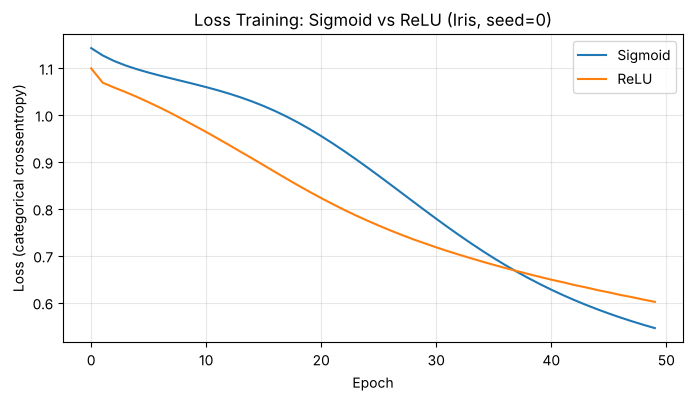

In [ ]:
hasil_aktivasi = {}
hist_aktivasi = {}
for act in ['sigmoid', 'relu']:
    r, hist = run_iris(hidden=(10, 8), activation=act)
    hasil_aktivasi[act] = r
    hist_aktivasi[act] = hist

tabel_aktivasi = pd.DataFrame(hasil_aktivasi).T
tabel_aktivasi.index = ['Sigmoid', 'ReLU']
display(tabel_aktivasi)

plt.figure(figsize=(8, 4))
plt.plot(hist_aktivasi['sigmoid']['loss'], label='Sigmoid')
plt.plot(hist_aktivasi['relu']['loss'], label='ReLU')
plt.xlabel('Epoch')
plt.ylabel('Loss (categorical crossentropy)')
plt.title('Loss Training: Sigmoid vs ReLU (Iris, seed=0)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Analisis Tugas 3
Arsitektur 10-8-3, rata-rata 5 seed, 50 epoch:

| Aktivasi hidden | Loss train | Loss test | Akurasi test (rata-rata) |
|---|---|---|---|
| Sigmoid | 0,5841 | 0,5799 | 82,0% |
| ReLU | 0,3232 | 0,3209 | **94,0%** |

- ReLU menghasilkan loss yang lebih rendah dan akurasi yang lebih tinggi pada jumlah epoch yang sama. Dari grafik, loss sigmoid turun lebih lambat.
- Alasannya: gradien sigmoid mengecil saat nilainya jenuh (mendekati 0 atau 1) sehingga pembaruan bobot lambat, sedangkan gradien ReLU bernilai 1 untuk input positif sehingga pelatihan lebih cepat.
- Dengan epoch yang lebih banyak, sigmoid kemungkinan dapat mendekati hasil ReLU, tetapi ReLU lebih efisien untuk pelatihan 50 epoch ini.

---
# Praktikum 3
## JST dengan Keras untuk Regresi: Prediksi Harga Rumah

## Langkah 1 - Import Library dan Buat Dataset
Dataset dummy sederhana berisi luas rumah dan harga.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

# Contoh dataset (buat dummy data)
data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})

X = data[['luas']]
y = data[['harga']]

## Langkah 2 - Normalisasi dan Split Data
Fitur dan target distandardisasi agar skala nilainya seragam sehingga pelatihan lebih stabil.

In [ ]:
# Normalisasi
scaler = StandardScaler()
X = scaler.fit_transform(X)
y = scaler.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

## Langkah 3 - Bangun Model
Karena ini kasus regresi, output layer hanya 1 neuron tanpa fungsi aktivasi.

In [ ]:
# Model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
    tf.keras.layers.Dense(1)
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## Langkah 4 - Kompilasi dan Latih Model
Loss yang dipakai adalah MSE (*mean squared error*).

In [ ]:
model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=100)

Epoch 1/100


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 439ms/step - loss: 2.1847

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 456ms/step - loss: 2.1847


Epoch 2/100


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 2.1686

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 2.1686


... (290 outputs left out)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - loss: 1.0496


Epoch 100/100


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 1.0414

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - loss: 1.0414


## Langkah 5 - Evaluasi

In [ ]:
# Evaluasi
print("Prediksi:", model.predict(X_test))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


Prediksi: [[-0.37271324]]


## Tugas 4
- Ubah learning rate.
- Bandingkan hasil loss.

Model dan data sama dengan di atas (pembagian data dibuat tetap dengan `random_state=42`), hanya *learning rate* optimizer Adam yang diubah.
Default Adam pada Keras adalah 0,001.

,Loss train (epoch 1),Loss train (epoch 100),Loss test
Learning rate,,,
0.0001,1.066133,0.988751,0.905758
0.0010,1.066133,0.600234,0.477486
0.0100,1.066133,0.001676,0.090521
0.1000,1.066133,0.000010,0.027424
1.0000,1.066133,0.250079,1.981616


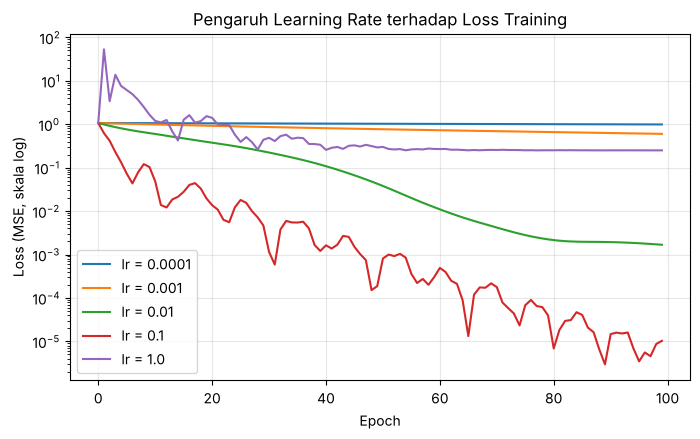

In [ ]:
X_tr_d, X_te_d, y_tr_d, y_te_d = train_test_split(X, y, test_size=0.2, random_state=42)

def run_lr(lr, epochs=100):
    tf.keras.utils.set_random_seed(42)
    m = tf.keras.Sequential([
        tf.keras.Input(shape=(1,)),
        tf.keras.layers.Dense(10, activation='relu'),
        tf.keras.layers.Dense(1)
    ])
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss='mse')
    h = m.fit(X_tr_d, y_tr_d, epochs=epochs, verbose=0)
    return h.history['loss'], m.evaluate(X_te_d, y_te_d, verbose=0)

lr_list = [0.0001, 0.001, 0.01, 0.1, 1.0]
hasil_lr = {lr: run_lr(lr) for lr in lr_list}

tabel_lr = pd.DataFrame({
    'Learning rate': lr_list,
    'Loss train (epoch 1)': [hasil_lr[lr][0][0] for lr in lr_list],
    'Loss train (epoch 100)': [hasil_lr[lr][0][-1] for lr in lr_list],
    'Loss test': [hasil_lr[lr][1] for lr in lr_list],
}).set_index('Learning rate')
display(tabel_lr)

plt.figure(figsize=(8, 4.5))
for lr in lr_list:
    plt.plot(hasil_lr[lr][0], label=f'lr = {lr}')
plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE, skala log)')
plt.title('Pengaruh Learning Rate terhadap Loss Training')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Analisis Tugas 4
Loss setelah 100 epoch dengan optimizer Adam (loss epoch pertama sama untuk semua, yaitu 1,066, karena bobot awal sama):

| Learning rate | Loss train (epoch 100) | Loss test |
|---|---|---|
| 0,0001 | 0,9888 | 0,9058 |
| 0,001 (default) | 0,6002 | 0,4775 |
| 0,01 | 0,0017 | 0,0905 |
| 0,1 | **0,00001** | **0,0274** |
| 1,0 | 0,2501 | 1,9816 |

- **Learning rate terlalu kecil (0,0001 dan 0,001):** loss turun sangat lambat, model belum selesai belajar setelah 100 epoch (underfitting).
- **Learning rate sedang (0,01 dan 0,1):** loss turun cepat dan mencapai nilai paling kecil. Pada data dummy ini 0,1 memberi hasil terbaik.
- **Learning rate terlalu besar (1,0):** langkah pembaruan terlalu besar sehingga loss berayun dan tidak turun dengan baik, hasil test paling buruk.
- Catatan: data test hanya 1 sampel, jadi loss test hanya gambaran kasar. Pada data nyata learning rate 0,1 biasanya terlalu besar untuk Adam, dan nilai sekitar 0,001 sampai 0,01 lebih aman.

## Prediksi Harga Rumah dengan Dataset Boston
Praktikum berikut memakai data Boston untuk memprediksi harga rumah (target `medv`, dalam ribuan dolar) dengan 13 fitur.
> Dataset yang sama (506 sampel, 13 fitur + target `medv`) dimuat dari salinan CSV publik dengan `pd.read_csv`. Bagian lain kode tidak diubah.

Ukuran data: (506, 14)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


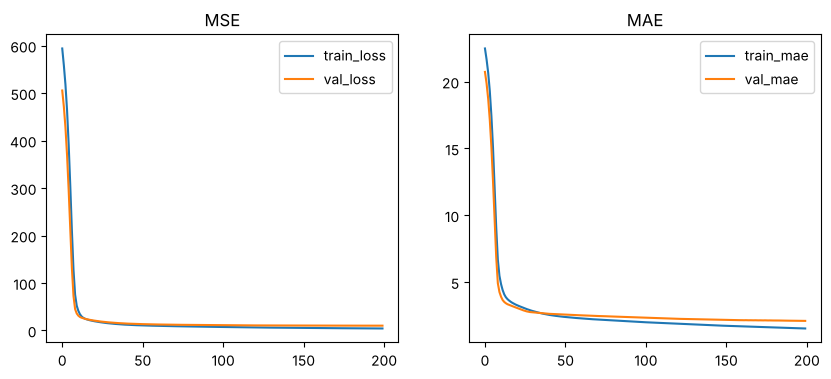

1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


RMSE: 3.1833410631709365


In [ ]:
# MLP regresi (Keras)
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

# 1. Load
# [Perbaikan] load_boston() sudah dihapus dari scikit-learn, data dimuat dari CSV
url = 'https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv'
data = pd.read_csv(url)
X = data.drop(columns='medv').values; y = data['medv'].values
print("Ukuran data:", data.shape)

# 2. Preprocess
scaler = StandardScaler(); Xs = scaler.fit_transform(X)
X_train, X_val, y_train, y_val = train_test_split(Xs, y, test_size=0.2, random_state=42)

# 3. Build model
model = Sequential([
Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
Dense(32, activation='relu'),
Dense(1)
])
model.compile(optimizer=Adam(1e-3), loss='mse', metrics=['mae'])

# 4. Train
h = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=200, batch_size=32, verbose=0)

# 5. Plot
plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.plot(h.history['loss'], label='train_loss'); plt.plot(h.history['val_loss'], label='val_loss'); plt.legend(); plt.title('MSE')
plt.subplot(1,2,2); plt.plot(h.history['mae'], label='train_mae'); plt.plot(h.history['val_mae'], label='val_mae'); plt.legend(); plt.title('MAE')
plt.show()

from sklearn.metrics import mean_squared_error
pred = model.predict(X_val)
print('RMSE:', np.sqrt(mean_squared_error(y_val, pred)))

### Analisis Dataset Boston
- Hasil evaluasi: **RMSE = 3,18** pada data validasi. Karena target `medv` dalam ribuan dolar, rata-rata kesalahan prediksi sekitar US$3.180.
- Dari grafik, MSE dan MAE turun sangat tajam pada sekitar 15 epoch pertama. Setelah itu loss data latih terus turun pelan, sedangkan loss validasi hampir datar, sehingga terbentuk selisih kecil antara keduanya sebagai tanda awal *overfitting*. Pelatihan 200 epoch sudah lebih dari cukup untuk model ini.
- Hasil dapat sedikit berbeda tiap run karena inisialisasi bobot acak (tanpa seed).

---
# Tugas Praktikum
## Klasifikasi Angka Tulisan Tangan (MNIST) dengan JST

## Langkah 1 - Load dan Preprocessing Dataset MNIST
Dataset MNIST berisi 60.000 gambar latih dan 10.000 gambar uji berukuran 28x28 piksel (angka 0-9). Nilai piksel dinormalisasi dari 0-255 menjadi 0-1, dan label diubah ke *one-hot encoding* (10 kelas).

In [ ]:
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical

# 1. Load dataset MNIST
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Normalisasi data (0-255 → 0-1)
X_train = X_train / 255.0
X_test = X_test / 255.0

# One-hot encoding label
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape, "| y_test :", y_test.shape)

X_train: (60000, 28, 28) | y_train: (60000, 10)
X_test : (10000, 28, 28) | y_test : (10000, 10)


## Langkah 2 - Bangun Model JST (2 Hidden Layer)
- `Flatten`: mengubah gambar 28x28 menjadi vektor 784 nilai.
- Hidden layer 1: 128 neuron, ReLU.
- Hidden layer 2: 64 neuron, ReLU.
- Output layer: 10 neuron (satu per digit), softmax.

In [ ]:
# 2. Bangun model JST
model = Sequential([
    # Ubah gambar 28x28 menjadi vektor
    Flatten(input_shape=(28, 28)),
    # Hidden layer 1
    Dense(128, activation='relu'),
    # Hidden layer 2
    Dense(64, activation='relu'),
    # Output layer (10 kelas)
    Dense(10, activation='softmax')
])
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_38"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_108 (Dense)               │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_109 (Dense)               │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_110 (Dense)               │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

## Langkah 3 - Kompilasi Model
Optimizer Adam, loss `categorical_crossentropy` (karena label one-hot), dan metrik akurasi.

In [ ]:
# 3. Kompilasi model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

## Langkah 4 - Latih Model
Pelatihan 10 epoch dengan `batch_size=32`. Sebanyak 10% data latih dipakai sebagai data validasi untuk memantau overfitting. Waktu pelatihan dicatat untuk perbandingan pada eksperimen berikutnya.

In [ ]:
import time

# 4. Latih model
tf.keras.utils.set_random_seed(42)
mulai = time.time()
history = model.fit(X_train, y_train, epochs=10, batch_size=32, validation_split=0.1)
waktu_dasar = time.time() - mulai
print(f"Waktu pelatihan: {waktu_dasar:.1f} detik")

Epoch 1/10


   1/1688 ━━━━━━━━━━━━━━━━━━━━ 16:43 595ms/step - accuracy: 0.0625 - loss: 2.3650

  32/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5381 - loss: 1.6256     

  66/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6709 - loss: 1.1409

 105/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.7348 - loss: 0.9072

 143/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.7692 - loss: 0.7800

... (513 outputs left out)

1646/1688 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9927 - loss: 0.0213

1673/1688 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9927 - loss: 0.0216

1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9927 - loss: 0.0215 - val_accuracy: 0.9802 - val_loss: 0.1047


Waktu pelatihan: 39.5 detik


## Langkah 5 - Evaluasi Model

In [ ]:
# 5. Evaluasi model
loss, acc = model.evaluate(X_test, y_test)
print(f"Akurasi pada data uji: {acc:.4f}")

  1/313 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 1.0000 - loss: 0.0319

 39/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9744 - loss: 0.1390 

 78/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9675 - loss: 0.1390

118/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9669 - loss: 0.1462

155/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9643 - loss: 0.1566

197/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9670 - loss: 0.1424

238/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9709 - loss: 0.1265

280/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9735 - loss: 0.1150

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9736 - loss: 0.1168

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9736 - loss: 0.1168


Akurasi pada data uji: 0.9736


## Eksperimen Parameter Lain
Sesuai soal, dicoba beberapa konfigurasi untuk membandingkan akurasi dan waktu pelatihan:
- Mengubah jumlah neuron hidden layer (256 dan 128).
- Menambah satu hidden layer lagi (menjadi 3 hidden layer).
- Fungsi aktivasi **Sigmoid** vs **ReLU**.

Semua konfigurasi dilatih dengan `seed`, optimizer, `epochs=10`, dan `batch_size=32` yang sama.

In [ ]:
def run_mnist(hidden_units, activation, epochs=10, batch_size=32):
    tf.keras.utils.set_random_seed(42)
    m = Sequential([Flatten(input_shape=(28, 28))]
                   + [Dense(u, activation=activation) for u in hidden_units]
                   + [Dense(10, activation='softmax')])
    m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

    mulai = time.time()
    h = m.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, validation_split=0.1, verbose=0)
    waktu = time.time() - mulai

    l_te, a_te = m.evaluate(X_test, y_test, verbose=0)
    return {
        'Jumlah parameter': m.count_params(),
        'Akurasi train': h.history['accuracy'][-1],
        'Akurasi validasi': h.history['val_accuracy'][-1],
        'Akurasi test': a_te,
        'Loss test': l_te,
        'Waktu latih (detik)': waktu,
    }, h.history

konfig_mnist = {
    '128-64 ReLU (awal)':          ((128, 64), 'relu'),
    '256-128 ReLU':                ((256, 128), 'relu'),
    '256-128-64 ReLU (3 hidden)':  ((256, 128, 64), 'relu'),
    '128-64 Sigmoid':              ((128, 64), 'sigmoid'),
    '256-128 Sigmoid':             ((256, 128), 'sigmoid'),
    '256-128-64 Sigmoid (3 hidden)': ((256, 128, 64), 'sigmoid'),
}

hasil_mnist = {}
hist_mnist = {}
for nama, (units, act) in konfig_mnist.items():
    hasil_mnist[nama], hist_mnist[nama] = run_mnist(units, act)
    print(f"selesai: {nama}")

tabel_mnist = pd.DataFrame(hasil_mnist).T
tabel_mnist.index.name = 'Konfigurasi'
tabel_mnist.style.format({
    'Jumlah parameter': '{:,.0f}',
    'Akurasi train': '{:.4f}', 'Akurasi validasi': '{:.4f}', 'Akurasi test': '{:.4f}',
    'Loss test': '{:.4f}', 'Waktu latih (detik)': '{:.1f}',
})

selesai: 128-64 ReLU (awal)


selesai: 256-128 ReLU


selesai: 256-128-64 ReLU (3 hidden)


selesai: 128-64 Sigmoid


selesai: 256-128 Sigmoid


selesai: 256-128-64 Sigmoid (3 hidden)


,Jumlah parameter,Akurasi train,Akurasi validasi,Akurasi test,Loss test,Waktu latih (detik)
Konfigurasi,,,,,,
128-64 ReLU (awal),"109,386",0.9929,0.9710,0.9705,0.1333,43.1
256-128 ReLU,"235,146",0.9946,0.9785,0.9772,0.1104,52.0
256-128-64 ReLU (3 hidden),"242,762",0.9931,0.9812,0.9785,0.0963,49.1
128-64 Sigmoid,"109,386",0.9952,0.9788,0.9762,0.0797,42.4
256-128 Sigmoid,"235,146",0.9977,0.9745,0.9734,0.1008,51.5
256-128-64 Sigmoid (3 hidden),"242,762",0.9954,0.9755,0.9717,0.1093,51.2


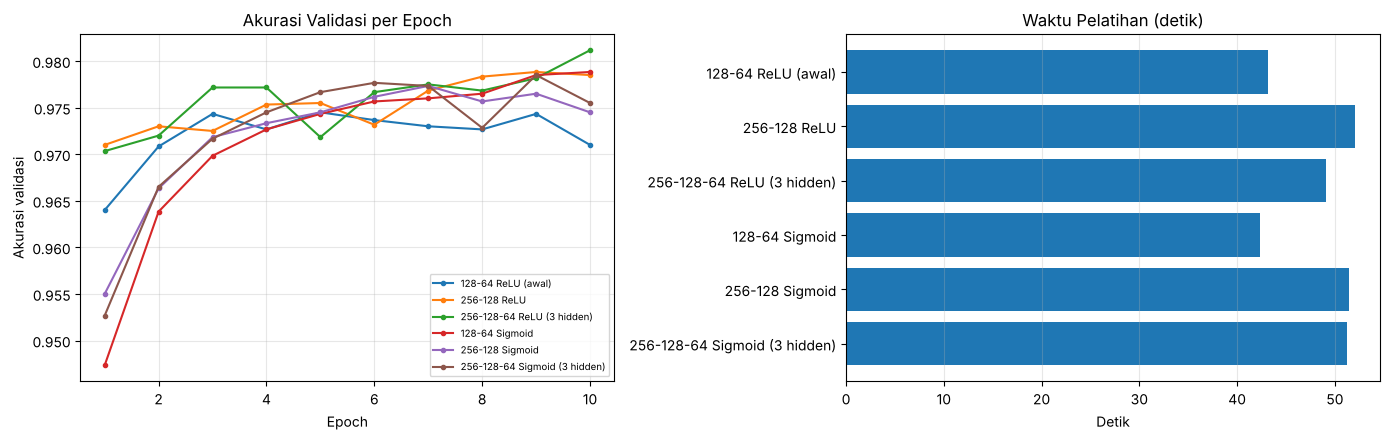

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

for nama in konfig_mnist:
    ax[0].plot(range(1, 11), hist_mnist[nama]['val_accuracy'], marker='o', markersize=3, label=nama)
ax[0].set_title('Akurasi Validasi per Epoch')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Akurasi validasi')
ax[0].legend(fontsize=7)
ax[0].grid(alpha=0.3)

ax[1].barh(list(konfig_mnist.keys()), tabel_mnist['Waktu latih (detik)'])
ax[1].set_title('Waktu Pelatihan (detik)')
ax[1].set_xlabel('Detik')
ax[1].invert_yaxis()
ax[1].grid(alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

### Analisis Tugas Praktikum (MNIST)
Model dasar (128-64, ReLU, 10 epoch) pada Langkah 5 mencapai akurasi uji **97,36%**. Hasil perbandingan konfigurasi (10 epoch, `batch_size=32`, seed sama):

| Konfigurasi | Parameter | Akurasi train | Akurasi test | Loss test | Waktu latih (detik) |
|---|---|---|---|---|---|
| 128-64 ReLU (awal) | 109.386 | 99,29% | 97,05% | 0,1333 | 43,1 |
| 256-128 ReLU | 235.146 | 99,46% | 97,72% | 0,1104 | 52,0 |
| 256-128-64 ReLU (3 hidden) | 242.762 | 99,31% | **97,85%** | 0,0963 | 49,1 |
| 128-64 Sigmoid | 109.386 | 99,52% | 97,62% | 0,0797 | 42,4 |
| 256-128 Sigmoid | 235.146 | 99,77% | 97,34% | 0,1008 | 51,5 |
| 256-128-64 Sigmoid (3 hidden) | 242.762 | 99,54% | 97,17% | 0,1093 | 51,2 |

- **Jumlah neuron dan hidden layer:** pada ReLU, menambah neuron (256-128) menaikkan akurasi uji dari 97,05% ke 97,72%, dan menambah satu hidden layer menaikkannya lagi ke 97,85%. Kenaikannya kecil, sedangkan jumlah parameter lebih dari dua kali lipat dan waktu latih naik sekitar 6 sampai 9 detik (sekitar 15-20%).
- **Sigmoid vs ReLU:** ReLU lebih baik pada 2 dari 3 pasangan konfigurasi, dan selisihnya makin besar saat jaringan lebih dalam (3 hidden layer: 97,85% vs 97,17%). Ini sejalan dengan gradien sigmoid yang mengecil pada jaringan dalam. Waktu latih keduanya hampir sama. Pada 128-64, sigmoid justru sedikit lebih baik (97,62% vs 97,05%).
- **Overfitting:** akurasi train (99,3% sampai 99,8%) lebih tinggi sekitar 2 sampai 2,5 poin dibanding akurasi test pada semua konfigurasi, jadi model mulai menghafal data latih.
- **Kesimpulan:** konfigurasi dengan akurasi uji tertinggi adalah 256-128-64 ReLU (97,85%). Untuk efisiensi, 128-64 ReLU sudah cukup baik (sekitar 97%) dengan parameter dan waktu paling sedikit.